In [34]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt

In [35]:
X,y = make_regression(n_samples=100,n_features=1,n_informative=1,n_targets=1,noise=20,random_state=2)

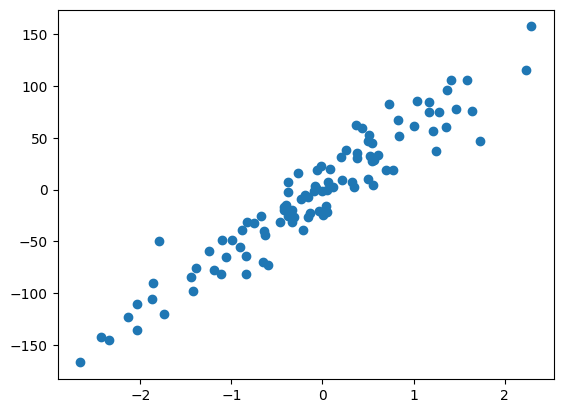

In [36]:
plt.scatter(X,y)

In [37]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X,y)

LinearRegression()

In [38]:
print(lr.coef_)
print(lr.intercept_)

[58.11865999]
0.5334392393890033


In [39]:
from sklearn.linear_model import Ridge
rg = Ridge(alpha=10)
rg.fit(X,y)

Ridge(alpha=10)

In [40]:
print(rg.coef_)
print(rg.intercept_)

[53.17425635]
0.02050119898896785


In [41]:
rg1 = Ridge(alpha=100)
rg1.fit(X,y)

Ridge(alpha=100)

In [42]:
print(rg1.coef_)
print(rg1.intercept_)

[30.11564938]
-2.371624834224592


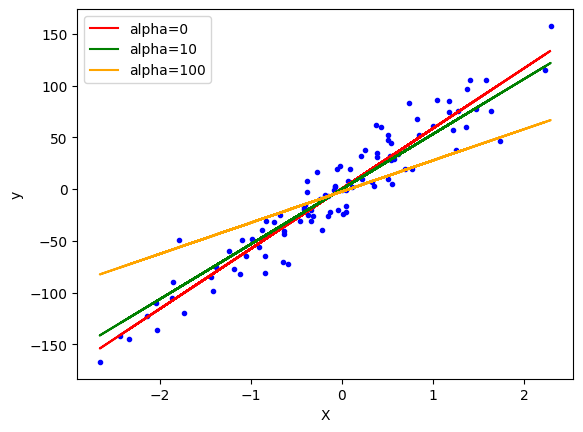

In [43]:
plt.plot(X,y,'b.')
plt.plot(X,lr.predict(X),color='red',label='alpha=0')
plt.plot(X,rg.predict(X),color='green',label='alpha=10')
plt.plot(X,rg1.predict(X),color='orange',label='alpha=100')

plt.xlabel('X')
plt.ylabel('y')

plt.legend()

plt.show()

In [44]:
class MeraRidge1D:
    def __init__(self,alpha=0.1):
        self.alpha = alpha
        self.coef_ = None
        self.intercept_ = None

    def fit(self,X_train,y_train):
        X_train = X_train.ravel()
        y_train = y_train.ravel()
        self.coef_ = np.sum((y_train - y_train.mean())*(X_train - X_train.mean()))/(self.alpha + np.sum((X_train - X_train.mean())**2))
        self.intercept_ = y_train.mean() - self.coef_ * X_train.mean()

    def predict(self,X_test):
        X_test = X_test.ravel()
        return self.coef_*X_test + self.intercept_

In [45]:
rg2 = MeraRidge1D(alpha=10)
rg2.fit(X,y)
print(rg2.coef_)
print(rg2.intercept_)

53.17425634972927
0.020501198988966074


In [46]:
from sklearn.datasets import load_diabetes
X,y = load_diabetes(return_X_y=True)

In [47]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [ ]:
from sklearn.linear_model import Ridge

rg3 = Ridge(alpha=0.1, solver='cholesky')

rg3.fit(X_train,y_train)

Ridge(alpha=0.1, solver='cholesky')

In [ ]:
y_pred = rg3.predict(X_test)
from sklearn.metrics import r2_score

print(r2_score(y_test, y_pred))

0.4519949419719548


In [ ]:
print(rg3.coef_)
print(rg3.intercept_)

[   6.64373321 -172.23747375  485.52958514  314.67584612  -72.94020918
  -80.58868817 -174.46352722   83.61470987  484.36531622   73.58509056]
151.92546856900984


In [53]:
class MeraRidgenD:
    def __init__(self, alpha = 0.1):
        self.alpha = alpha
        self.coef_ = None
        self.intercept_ = None

    def fit(self, X_train, y_train):
        X_train = np.insert(X_train,0,1,axis=1)
        b = np.linalg.inv((np.dot(X_train.T,X_train) + self.alpha * np.eye(X_train.shape[1]))).dot(X_train.T).dot(y_train)
        self.intercept_ = b[0]
        self.coef_ = b[1:]

    def predict(self, X_test):
        return np.dot(X_test,self.coef_) + self.intercept_

In [54]:
rg4 = MeraRidgenD(alpha=0.1)
rg4.fit(X_train,y_train)

y_pred = rg4.predict(X_test)

print(r2_score(y_test,y_pred))

0.4519719082031617


In [55]:
print(rg4.coef_)
print(rg4.intercept_)

[   6.64970105 -172.2493574   485.49941498  314.68335483  -72.93919534
  -80.6014393  -174.45279965   83.5733994   484.39865564   73.58483208]
151.88221592211525
